In [1]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.layers import Conv2D, Dropout, MaxPooling2D, Flatten, Dense
import numpy as np
import matplotlib.pyplot as plt

In [20]:
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

In [21]:
train_images.shape

(60000, 28, 28)

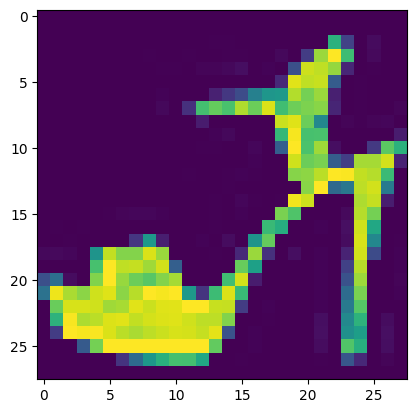

In [22]:
plt.imshow(train_images[9])

In [23]:
# Limpiar data
train_images = train_images.astype('float32') / 255
test_images = test_images.astype('float32') / 255

In [24]:
train_images = train_images.reshape(train_images.shape[0],28,28,1) # Quedamos con un canal
test_images = test_images.reshape(test_images.shape[0],28,28,1)

In [25]:
train_labels[0] # Hacer one-hot encoding

np.uint8(9)

In [26]:
train_labels = tf.keras.utils.to_categorical(train_labels, 10) # Estandarizar los datos
test_labels = tf.keras.utils.to_categorical(test_labels, 10)

In [27]:
train_labels[0]

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 1.])

In [29]:
# Modelo
model = tf.keras.Sequential()
model.add(Conv2D(filters=64, kernel_size= 2, padding = 'same', activation='relu', input_shape=(28,28,1)))
model.add(MaxPooling2D(pool_size=2)) # Max pooling
model.add(Dropout(0.3))
model.add(Conv2D(filters=32, kernel_size= 2, padding = 'same', activation='relu'))
model.add(MaxPooling2D(pool_size=2)) # Max pooling
model.add(Dropout(0.3))
model.add(Flatten()) # Aplanar los tensores para estar en serie
model.add(Dense(256, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(10, activation='softmax')) # Tener en cuentas el numero de salidas para la prediccion
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 64)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 14, 14, 32)          │           8,224 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 7, 7, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 7, 7, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 1568)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 256)                 │         401,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 412,778 (1.57 MB)

 Trainable params: 412,778 (1.57 MB)

 Non-trainable params: 0 (0.00 B)